In [2]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torchdiffeq import odeint
from scipy.integrate import solve_ivp
import tqdm

In [3]:
# PARAMETERS AND DATA PREPARATION
# LOTKA VOLTERRA MODEL
alpha, beta, delta, gamma = 1.5, 1.0, 1.0, 3.0

def f(X):
    x1, x2 = X[:,0], X[:,1]

    dx1_dt = alpha * x1 - beta * x1 * x2
    dx2_dt = delta * x1 * x2 - gamma * x2
    return torch.stack([dx1_dt, dx2_dt], dim=1)

X0 = [1.0, 1.0]
t_span = [0.0, 20.0]
t_eval = np.linspace(0.0, 20.0, 600)

sol_real = solve_ivp(
    lambda t, s: [alpha*s[0] - beta*s[0]*s[1], delta*s[0]*s[1] - gamma*s[1]], 
    t_span, X0, t_eval=t_eval
)

time = torch.tensor(t_eval, dtype=torch.float32)
X_real = torch.tensor(sol_real.y, dtype=torch.float32).T

# TAKENS EMBEDDINGS
num_lags = 1
num_delays = 16
def takenize(X, num_lags=num_lags, num_delays=num_delays):
    N, d = X.shape
    
    X_takens = X.unfold(dimension=0, size=num_delays, step=num_lags)
    X_takens = X_takens.flip(dims=[-1])
    X_takens = X_takens.transpose(1,2)
    X_takens = X_takens.reshape(X_takens.shape[0], -1)

    takens_idxs = torch.arange((num_delays - 1) * num_lags, N, num_lags)
    
    return X_takens, takens_idxs

X_takens, takens_idxs = takenize(X_real, num_lags=num_lags, num_delays=num_delays)

time_tak = time[takens_idxs]
X_real_tak = X_real[takens_idxs]
dXdt_tak = f(X_real_tak)

meanX_tak = X_takens.mean(dim=0, keepdim=True)
stdX_tak = X_takens.std(dim=0, keepdim=True)
X_norm_tak = (X_takens - meanX_tak) / stdX_tak

In [13]:
# MODEL DEFINITION
input_dim = 2 * num_delays
output_dim = 2

class TakensNeuralField(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, output_dim)
        )

    def forward(self, x):
        return self.net(x)

def compute_H(X):
    x1, x2 = X[:, 0], X[:, 1]
    eps = 1e-8
    return delta * x1 - gamma * torch.log(x1 + eps) + beta * x2 - alpha * torch.log(x2 + eps)

# TRAINING
model = TakensNeuralField()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

epochs = 20000
model.train()
progress_bar = tqdm.tqdm(range(epochs), desc=f"Starting training...")
min_loss = 1e6

lambda_physics = 2.0

for epoch in progress_bar:
    noise = torch.randn_like(X_real) * 0.05
    X_noisy = X_real + noise

    X_noisy_tak, _ = takenize(X_noisy, num_lags=num_lags, num_delays=num_delays)

    X_valid_noisy = X_real_tak + noise[takens_idxs]
    dXdt_noisy = f(X_valid_noisy)

    X_noisy_tak_norm = (X_noisy_tak - meanX_tak) / stdX_tak
    dXdt_pred = model(X_noisy_tak_norm)

    optimizer.zero_grad()
    loss = torch.mean((dXdt_pred - dXdt_noisy)**2)

    x1_noisy, x2_noisy = X_valid_noisy[:, 0], X_valid_noisy[:, 1]
    dH_dx1 = delta - (gamma / (x1_noisy + 1e-8))
    dH_dx2 = beta - (alpha / (x2_noisy + 1e-8))
    dH_dt_pred = dH_dx1 * dXdt_pred[:, 0] + dH_dx2 * dXdt_pred[:, 1]    
    loss += lambda_physics * torch.mean(dH_dt_pred**2)
    
    loss.backward()
    optimizer.step()

    current_loss = loss.item()

    if current_loss < min_loss:
        torch.save(model.state_dict(), "model_weights.pt")
        min_loss = current_loss

    if epoch % 50 == 0:
        progress_bar.set_postfix(loss=f"{current_loss:.6f}", min_loss=f"{min_loss:.6f}")

print("TRAINING SUCCESS!")

Starting training...: 100%|██████████| 20000/20000 [01:21<00:00, 246.39it/s, loss=0.001466, min_loss=0.001052]

TRAINING SUCCESS!


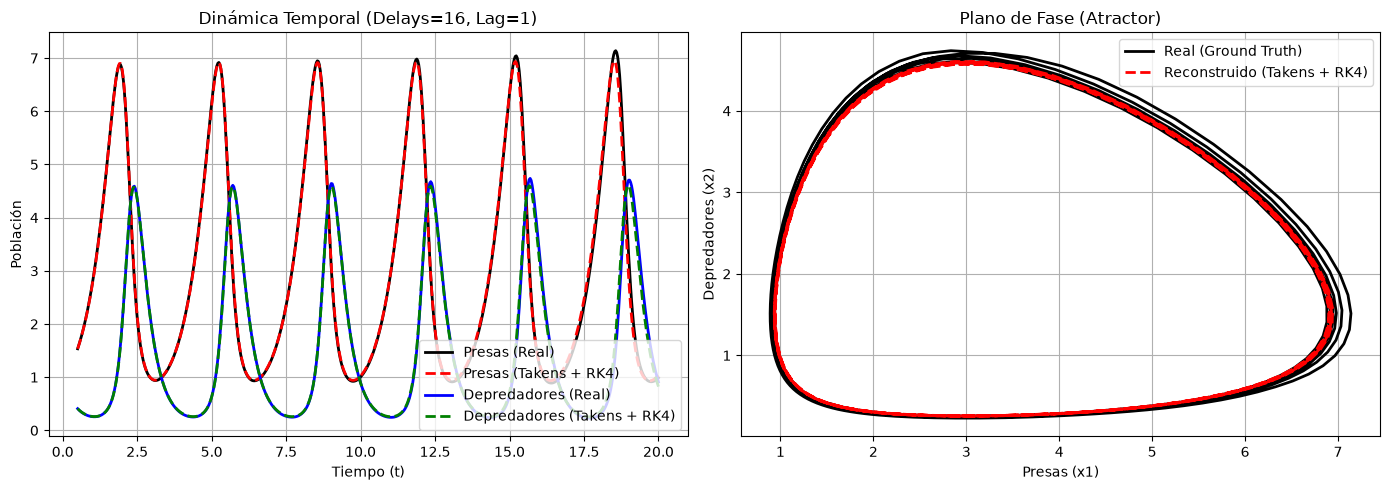

In [14]:
# ==========================================
# 5. EVALUACIÓN Y SIMULACIÓN MANUAL CON RK4 Y TAKENS
# ==========================================
eval_model = TakensNeuralField()
eval_model.load_state_dict(torch.load("model_weights.pt"))
eval_model.eval()

dt = t_eval[1]
# Configuramos el buffer de historial necesario para alimentar los 16 delays en el RK4
max_history_steps = (num_delays - 1) * num_lags
start_idx = max_history_steps

history = [X_real[start_idx - k].clone() for k in range(max_history_steps, -1, -1)]
pred_trajectory = [X_real[start_idx]]

def get_takens_input_eval(hist):
    # Extrae dinámicamente los últimos 16 estados respetando el lag
    elements = [hist[-1 - i * num_lags] for i in range(num_delays)]
    raw_emb = torch.cat(elements, dim=0).unsqueeze(0)
    return (raw_emb - meanX_tak) / stdX_tak

def takens_derivative(curr_state, hist_buffer):
    temp_hist = hist_buffer.copy()
    temp_hist[-1] = curr_state
    inp = get_takens_input_eval(temp_hist)
    with torch.no_grad():
        return eval_model(inp).squeeze(0)

# Bucle de integración manual RK4 hacia adelante en el tiempo
num_steps = len(t_eval) - start_idx
for step in range(num_steps - 1):
    x_n = history[-1]
    
    k1 = takens_derivative(x_n, history)
    k2 = takens_derivative(x_n + 0.5 * dt * k1, history)
    k3 = takens_derivative(x_n + 0.5 * dt * k2, history)
    k4 = takens_derivative(x_n + dt * k3, history)
    
    x_next = x_n + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)
    
    history.pop(0)
    history.append(x_next)
    pred_trajectory.append(x_next)

# Convertimos a numpy para la visualización
pred_trajectory = torch.stack(pred_trajectory).detach().numpy()
valid_t_eval = t_eval[start_idx:]
real_subset = X_real[start_idx:].numpy()

# ==========================================
# 6. VISUALIZACIÓN DE RESULTADOS
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfica 1: Dinámica Temporal
axes[0].plot(valid_t_eval, real_subset[:, 0], 'k-', label='Presas (Real)', linewidth=2)
axes[0].plot(valid_t_eval, pred_trajectory[:, 0], 'r--', label='Presas (Takens + RK4)', linewidth=2)
axes[0].plot(valid_t_eval, real_subset[:, 1], 'b-', label='Depredadores (Real)', linewidth=2)
axes[0].plot(valid_t_eval, pred_trajectory[:, 1], 'g--', label='Depredadores (Takens + RK4)', linewidth=2)
axes[0].set_title(f"Dinámica Temporal (Delays={num_delays}, Lag={num_lags})")
axes[0].set_xlabel("Tiempo (t)")
axes[0].set_ylabel("Población")
axes[0].legend(loc='lower right')
axes[0].grid(True)

# Gráfica 2: Plano de Fase (Atractor)
axes[1].plot(real_subset[:, 0], real_subset[:, 1], 'k-', label='Real (Ground Truth)', linewidth=2)
axes[1].plot(pred_trajectory[:, 0], pred_trajectory[:, 1], 'r--', label='Reconstruido (Takens + RK4)', linewidth=2)
axes[1].set_title("Plano de Fase (Atractor)")
axes[1].set_xlabel("Presas (x1)")
axes[1].set_ylabel("Depredadores (x2)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()